# Telco Customer Churn - Supervised Learning Case Study (CA-4)

**Task:** binary classification - predict whether a telecom customer will churn.
**Dataset:** Telco Customer Churn (IBM sample data, Kaggle `blastchar/telco-customer-churn`).

**Rubric map**
1. Problem understanding and EDA (missing values, outliers, distributions, correlations, encoding, 70/30 split)
2. Baseline models (Logistic Regression, Decision Tree, KNN) with Accuracy / Precision / Recall / F1 / Confusion Matrix
3. Advanced models (Random Forest, Gradient Boosting, XGBoost), GridSearchCV, cross-validation, ROC/AUC, SMOTE and class weights
4. Interpretation: final model justification, feature importance, business insights, limitations, future work, deployment demo

In [1]:
import warnings

import joblib
import numpy as np
import pandas as pd
from IPython.display import display

from churn import artifacts, config, data, eda, evaluate, interpret, models, plots, thresholds, tuning

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.4f}".format)
plots.set_style()

## 1. Problem understanding

Acquiring a new customer costs far more than retaining an existing one, so a churn model is only
useful if it **ranks at-risk customers well** and lets the business choose **how many to contact**.
Because only ~1 in 4 customers churns, plain accuracy is misleading (always predicting "No" scores ~73%).
We therefore judge models on ROC-AUC, PR-AUC, recall and F1, and tune the decision threshold explicitly.

## 2. Data exploration
### 2.1 Dataset size, feature types, target

In [2]:
raw = data.load_raw()
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
display(raw.head())
display(eda.overview(raw))

Rows: 7,043 | Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.8500,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.9500,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.8500,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3000,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7000,151.65,Yes


,dtype,missing,missing_pct,unique
customerID,str,0,0.0000,7043
gender,str,0,0.0000,2
SeniorCitizen,int64,0,0.0000,2
Partner,str,0,0.0000,2
Dependents,str,0,0.0000,2
tenure,int64,0,0.0000,73
PhoneService,str,0,0.0000,2
MultipleLines,str,0,0.0000,3
InternetService,str,0,0.0000,3
OnlineSecurity,str,0,0.0000,3


`TotalCharges` is stored as text. Pandas does not flag it as missing, so check for blank strings explicitly.

In [3]:
blank_total = raw["TotalCharges"].astype(str).str.strip().eq("")
print(f"TotalCharges dtype: {raw['TotalCharges'].dtype} | blank entries: {blank_total.sum()}")
display(raw.loc[blank_total, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

TotalCharges dtype: str | blank entries: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.5500,,No
753,3115-CZMZD,0,20.2500,,No
936,5709-LVOEQ,0,80.8500,,No
1082,4367-NUYAO,0,25.7500,,No
1340,1371-DWPAZ,0,56.0500,,No
3331,7644-OMVMY,0,19.8500,,No
3826,3213-VVOLG,0,25.3500,,No
4380,2520-SGTTA,0,20.0000,,No
5218,2923-ARZLG,0,19.7000,,No
6670,4075-WKNIU,0,73.3500,,No


All blank rows have `tenure == 0`: brand-new customers that have not been billed yet.
The correct value is therefore `0.0` (a deterministic rule applied in `data.clean_data`), not a statistical imputation.

In [4]:
df = data.clean_data(raw)

print(f"Unique customerID: {df['customerID'].is_unique} | duplicate rows: {df.duplicated().sum()}")
print(f"Remaining missing values: {int(df.isna().sum().sum())}")

feature_types = pd.Series(
    {
        "numeric (raw)": config.RAW_NUMERIC,
        "categorical": config.CATEGORICAL,
        "identifier (dropped)": [config.ID_COL],
        "target": [config.TARGET],
    }
)
display(feature_types.to_frame("columns"))
display(eda.overview(df))

Unique customerID: True | duplicate rows: 0
Remaining missing values: 0


,columns
numeric (raw),"[tenure, MonthlyCharges, TotalCharges]"
categorical,"[gender, SeniorCitizen, Partner, Dependents, P..."
identifier (dropped),[customerID]
target,[Churn]


,dtype,missing,missing_pct,unique
customerID,str,0,0.0000,7043
gender,str,0,0.0000,2
SeniorCitizen,str,0,0.0000,2
Partner,str,0,0.0000,2
Dependents,str,0,0.0000,2
tenure,int64,0,0.0000,73
PhoneService,str,0,0.0000,2
MultipleLines,str,0,0.0000,3
InternetService,str,0,0.0000,3
OnlineSecurity,str,0,0.0000,3


### 2.2 Target variable

,customers,share
Churn,,
No,5174,0.7346
Yes,1869,0.2654


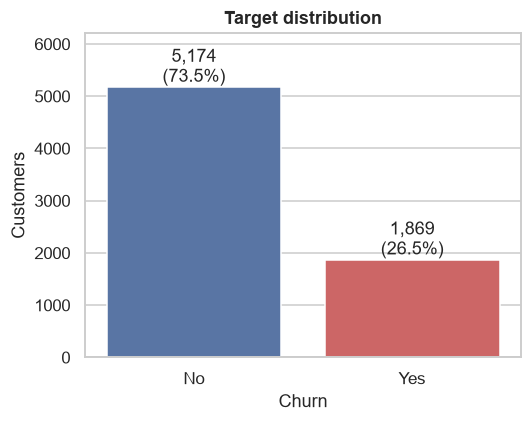

In [5]:
display(
    df[config.TARGET]
    .value_counts()
    .to_frame("customers")
    .assign(share=lambda t: t["customers"] / t["customers"].sum())
)
plots.plot_target_distribution(df[config.TARGET], name="01_target_distribution")

### 2.3 Distribution analysis

,count,mean,std,min,25%,50%,75%,max,skew
tenure,"7,043.0000",32.3711,24.5595,0.0000,9.0000,29.0000,55.0000,72.0000,0.2395
MonthlyCharges,"7,043.0000",64.7617,30.0900,18.2500,35.5000,70.3500,89.8500,118.7500,-0.2205
TotalCharges,"7,043.0000","2,279.7343","2,266.7945",0.0000,398.5500,"1,394.5500","3,786.6000","8,684.8000",0.9632


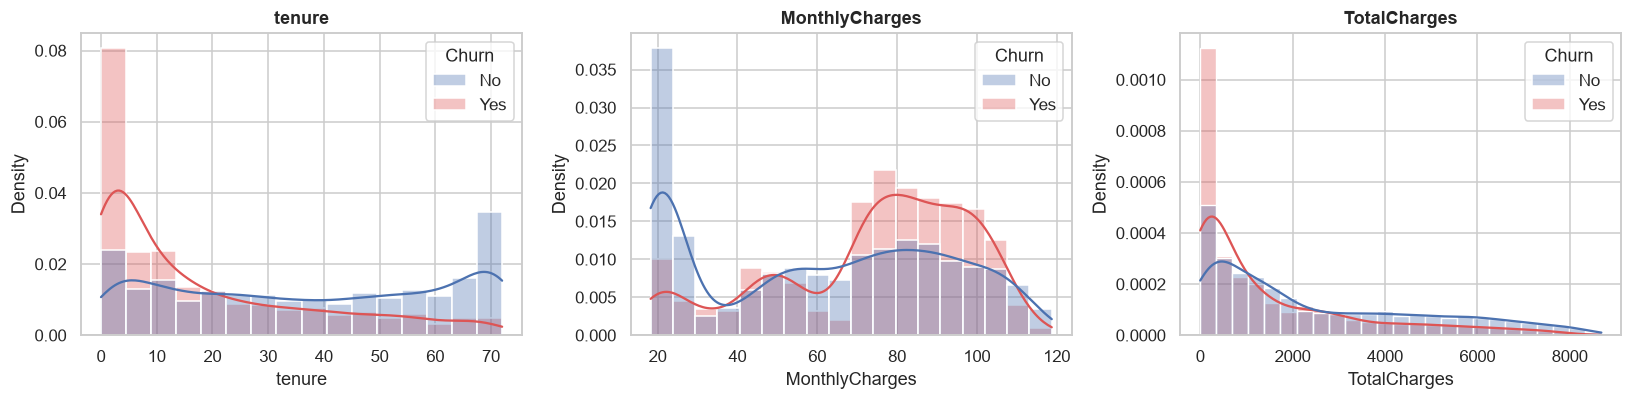

In [6]:
numeric_summary = df[config.RAW_NUMERIC].describe().T.join(df[config.RAW_NUMERIC].skew().rename("skew"))
display(numeric_summary)
plots.plot_numeric_distributions(df, config.RAW_NUMERIC, name="02_numeric_distributions")

### 2.4 Outlier detection (Tukey IQR fences)

,q1,q3,lower_fence,upper_fence,n_outliers,pct_outliers
column,,,,,,
tenure,9.0000,55.0000,-60.0000,124.0000,0,0.0000
MonthlyCharges,35.5000,89.8500,-46.0250,171.3750,0,0.0000
TotalCharges,398.5500,"3,786.6000","-4,683.5250","8,868.6750",0,0.0000


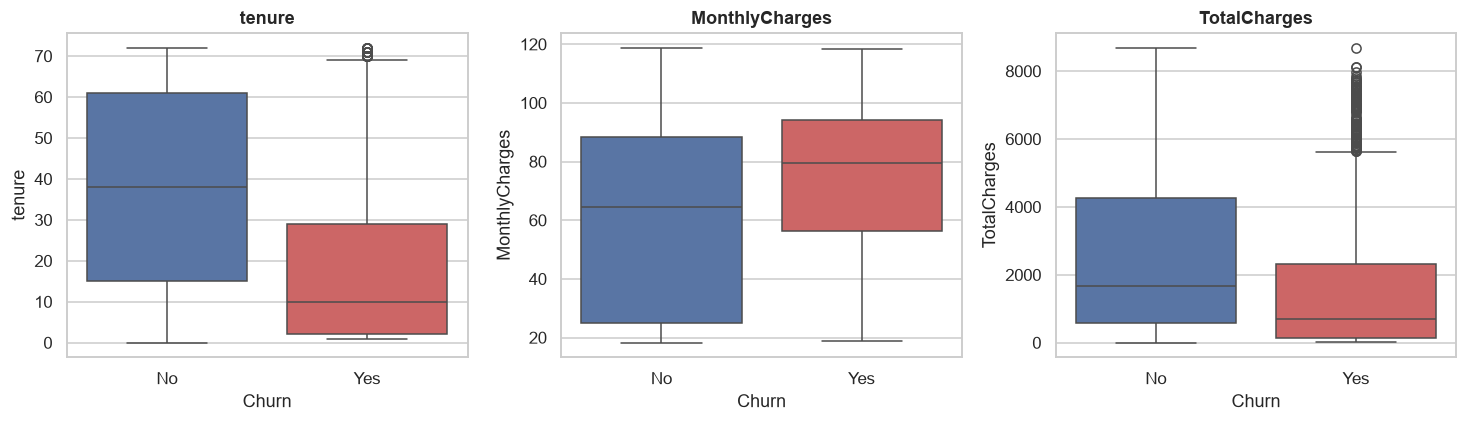

In [7]:
display(eda.iqr_outliers(df, config.RAW_NUMERIC))
plots.plot_boxplots(df, config.RAW_NUMERIC, name="03_boxplots")

Check the outlier table above. If few or no points fall outside the fences, no rows need removing: a long right
tail in `TotalCharges` is genuine (long-tenure, high-spend customers). We keep all rows and use `StandardScaler`,
which tree models ignore anyway.

### 2.5 Churn drivers by category

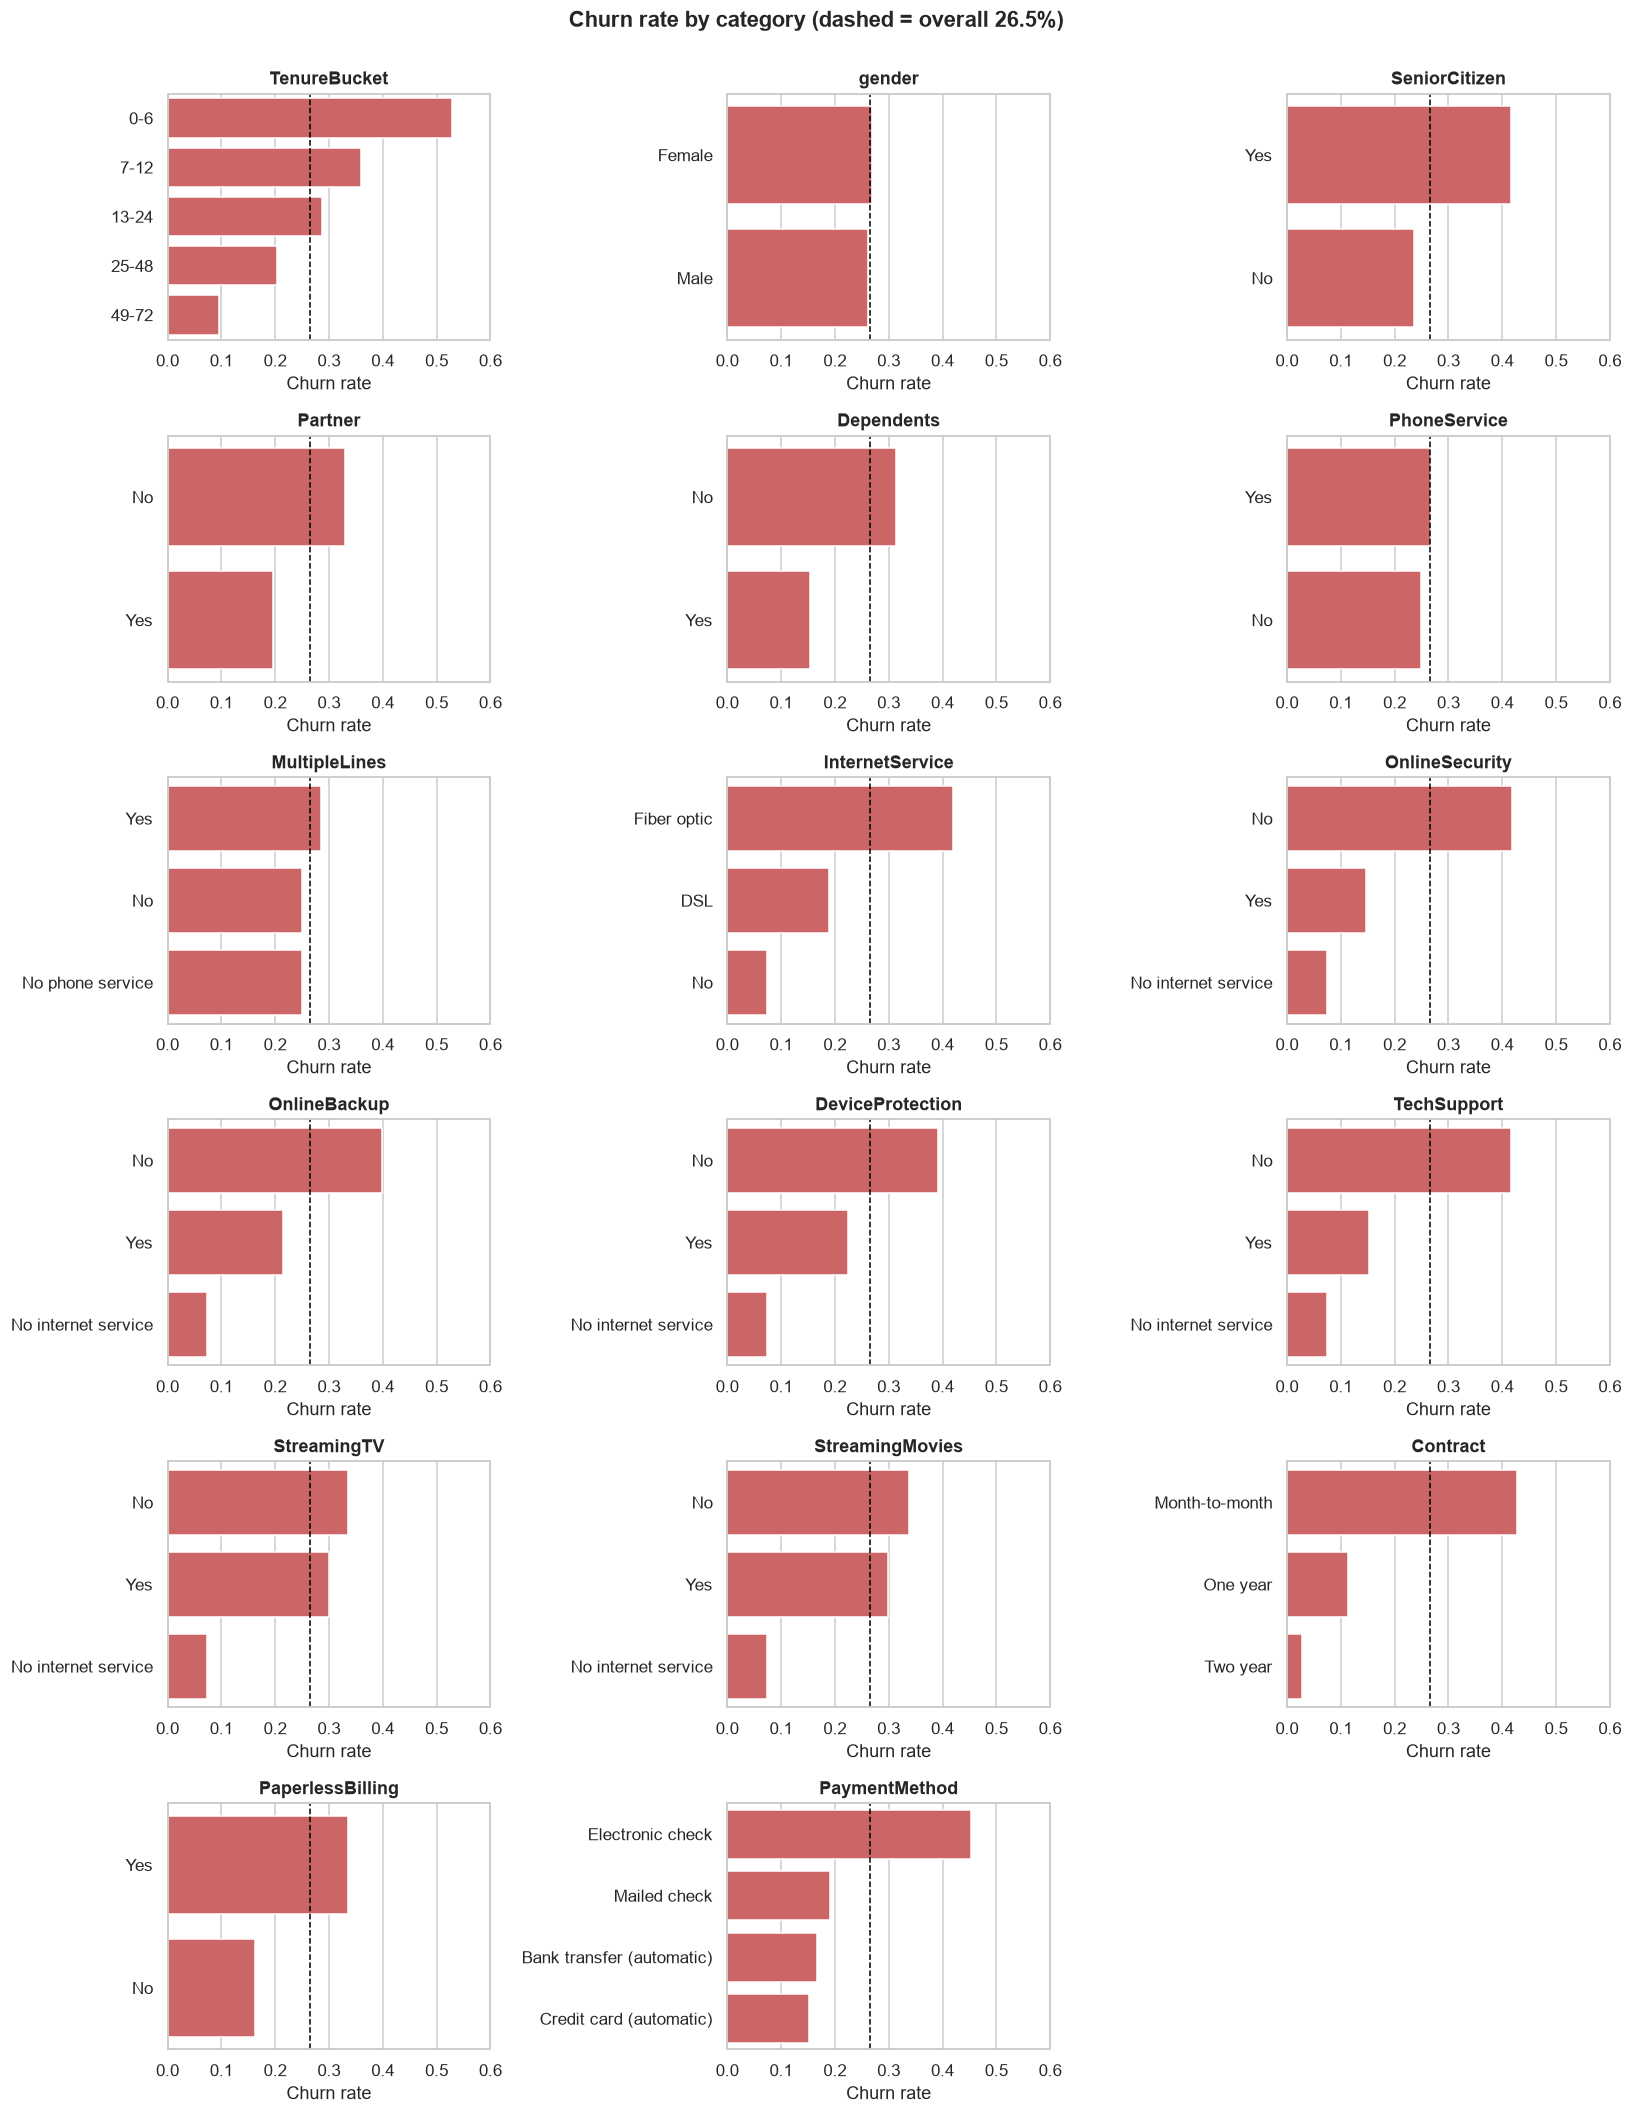

In [8]:
df_eda = df.assign(TenureBucket=eda.tenure_bucket(df["tenure"]))
plots.plot_churn_rate_grid(df_eda, ["TenureBucket", *config.CATEGORICAL], name="04_churn_rate_by_category")

In [9]:
display(eda.churn_rate_by(df_eda, "Contract"))
display(eda.churn_rate_by(df_eda, "PaymentMethod"))
display(eda.churn_rate_by(df_eda, "TenureBucket"))

,customers,churn_rate
Contract,,
Month-to-month,3875,0.4271
One year,1473,0.1127
Two year,1695,0.0283


,customers,churn_rate
PaymentMethod,,
Electronic check,2365,0.4529
Mailed check,1612,0.1911
Bank transfer (automatic),1544,0.1671
Credit card (automatic),1522,0.1524


,customers,churn_rate
TenureBucket,,
0-6,1481,0.5294
7-12,705,0.3589
13-24,1024,0.2871
25-48,1594,0.2039
49-72,2239,0.0951


### 2.6 Association with the target (chi-square and Cramér's V)

,chi2,p_value,dof,cramers_v
feature,,,,
Contract,"1,184.5966",0.0000,2,0.4098
OnlineSecurity,849.9990,0.0000,2,0.3470
TechSupport,828.1971,0.0000,2,0.3425
InternetService,732.3096,0.0000,2,0.3220
PaymentMethod,648.1423,0.0000,3,0.3027
OnlineBackup,601.8128,0.0000,2,0.2919
DeviceProtection,558.4194,0.0000,2,0.2811
StreamingMovies,375.6615,0.0000,2,0.2304
StreamingTV,374.2039,0.0000,2,0.2299


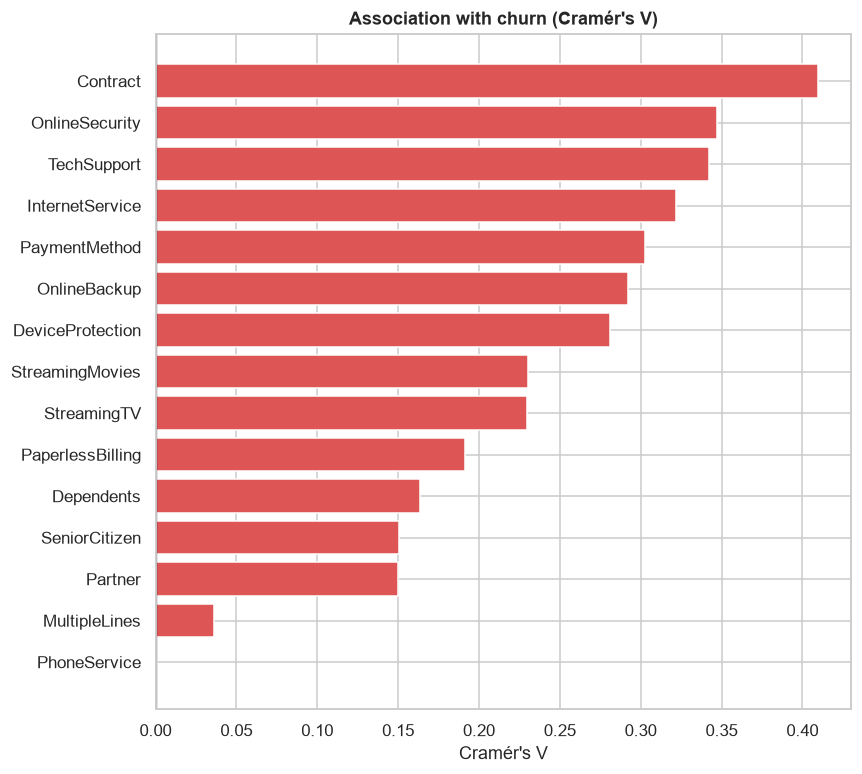

In [10]:
association = eda.chi2_table(df, config.CATEGORICAL, config.TARGET)
display(association)
plots.plot_ranked_bar(
    association["cramers_v"], "Association with churn (Cramér's V)", "Cramér's V", name="05_cramers_v"
)

### 2.7 Correlation analysis

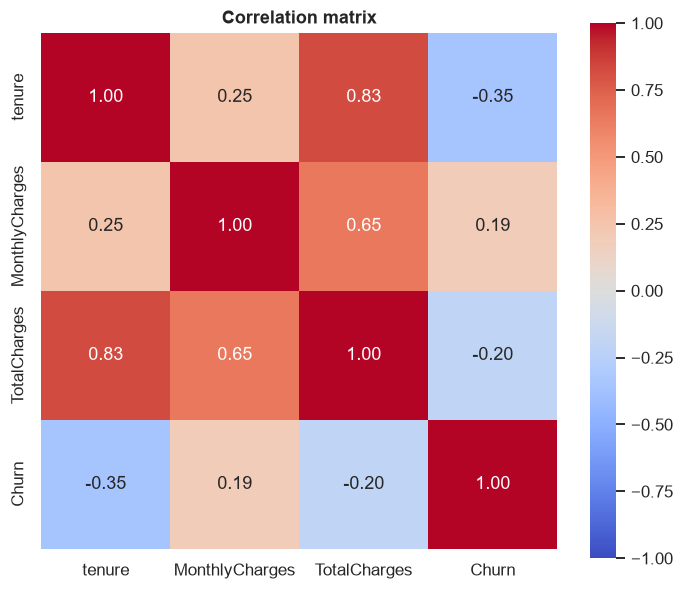

In [11]:
corr_frame = df[config.RAW_NUMERIC].assign(Churn=data.encode_target(df[config.TARGET]))
plots.plot_correlation_heatmap(corr_frame.corr(), name="06_correlation_numeric")

`tenure` and `TotalCharges` are strongly correlated (TotalCharges is roughly tenure x MonthlyCharges).
This is harmless for tree ensembles and tolerable for regularised Logistic Regression, but it is worth noting in the report.

## 3. Feature engineering, encoding and 70/30 split

Two stateless features are added: `n_addons` (number of internet add-on services) and `is_autopay`.
Encoding (one-hot, binary columns collapse to one indicator) and scaling are part of the model pipeline,
so they are fitted on training data only. The split is stratified to preserve the churn ratio.

In [12]:
df_model = data.add_features(df)
X_train, X_test, y_train, y_test = data.make_splits(df_model)

split_summary = pd.DataFrame(
    {
        "rows": [len(X_train), len(X_test)],
        "share": [len(X_train) / len(df_model), len(X_test) / len(df_model)],
        "churn_rate": [y_train.mean(), y_test.mean()],
    },
    index=["train", "test"],
)
display(split_summary)

,rows,share,churn_rate
train,4930,0.7000,0.2653
test,2113,0.3000,0.2655


Encoded training matrix: (4930, 42)


,tenure,MonthlyCharges,TotalCharges,n_addons,is_autopay,gender_Male,SeniorCitizen_Yes,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
5557,-1.1147,0.5043,-0.8365,-0.5731,-0.8805,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
2270,-1.1959,0.7242,-0.9077,-0.0358,-0.8805,0.0000,1.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000
6930,-1.1959,0.3373,-0.9096,-1.1105,1.1357,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000
2257,1.1171,0.5159,1.1103,1.0390,1.1357,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000
898,-0.8307,1.1227,-0.5151,1.0390,1.1357,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000


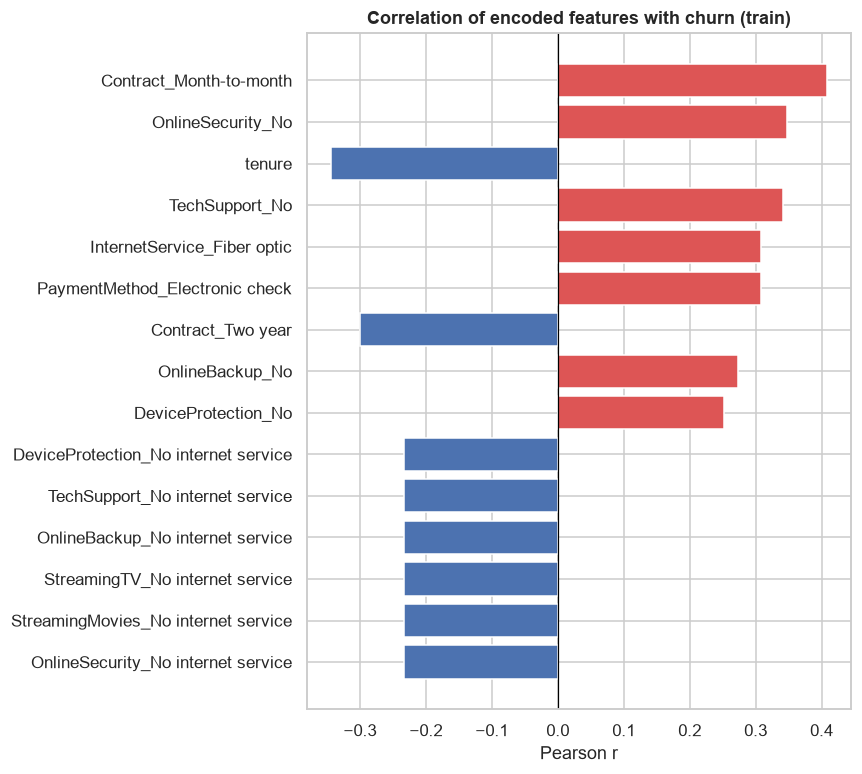

In [13]:
preprocessor = models.build_preprocessor().fit(X_train)
X_train_encoded = pd.DataFrame(
    preprocessor.transform(X_train), columns=preprocessor.get_feature_names_out(), index=X_train.index
)
print(f"Encoded training matrix: {X_train_encoded.shape}")
display(X_train_encoded.head())

target_corr = X_train_encoded.corrwith(y_train).dropna()
plots.plot_ranked_bar(
    target_corr, "Correlation of encoded features with churn (train)", "Pearson r", name="07_target_correlation"
)

## 4. Baseline models

Defaults only (no tuning), evaluated on the held-out 30% test set at the standard 0.5 threshold.
A `DummyClassifier` (always predicts the majority class) provides the floor every model must beat.

In [14]:
baselines = models.baseline_models()
for estimator in baselines.values():
    estimator.fit(X_train, y_train)

baseline_results = evaluate.evaluate_models(baselines, X_test, y_test)
display(baseline_results)

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
model,,,,,,,,,,,
Dummy,0.5000,0.7345,0.0000,0.0000,0.0000,0.5000,0.2655,1552,0,561,0
Logistic Regression,0.5000,0.8088,0.6660,0.5615,0.6093,0.8448,0.6418,1394,158,246,315
Decision Tree,0.5000,0.7265,0.4846,0.4759,0.4802,0.6468,0.3706,1268,284,294,267
KNN,0.5000,0.7681,0.5676,0.5312,0.5488,0.7831,0.5082,1325,227,263,298


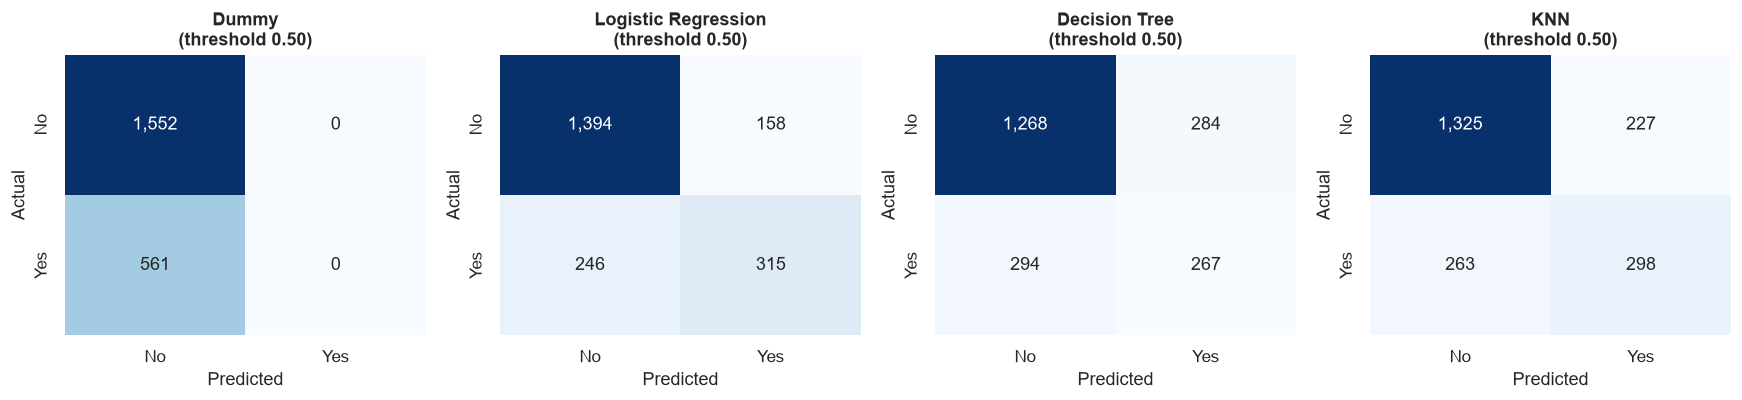

In [15]:
plots.plot_confusion_matrices(baselines, X_test, y_test, name="08_baseline_confusion_matrices")

**Interpretation (write after running; cover these points with your actual numbers)**
- Dummy accuracy equals the majority-class share, with recall 0: accuracy alone cannot be trusted here.
- Logistic Regression: best ranking (ROC-AUC), but recall on churners at 0.5 is well below precision.
- Decision Tree (unconstrained): near-perfect on train, weaker on test, so it overfits (compare train vs test).
- KNN: sensitive to the many one-hot dimensions, usually the weakest of the three on AUC.
- Conclusion: the gap between accuracy and recall motivates imbalance handling and threshold tuning.

### 4.1 Cross-validated baselines (5-fold stratified, training set)

In [16]:
display(tuning.cv_summary(baselines, X_train, y_train))

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Dummy,0.7347 ± 0.0005,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000
Logistic Regression,0.8028 ± 0.0104,0.6539 ± 0.0263,0.5481 ± 0.0307,0.5958 ± 0.0221,0.8445 ± 0.0115
Decision Tree,0.7363 ± 0.0105,0.5029 ± 0.0189,0.5291 ± 0.0340,0.5153 ± 0.0233,0.6716 ± 0.0170
KNN,0.7617 ± 0.0143,0.5559 ± 0.0296,0.5115 ± 0.0200,0.5326 ± 0.0230,0.7812 ± 0.0165


## 5. Advanced modelling

Random Forest, Gradient Boosting and XGBoost, each under three imbalance strategies:
`none`, `weights` (class_weight / scale_pos_weight) and `smote` (inside the pipeline, so synthetic samples are
created only from the training portion of each CV fold). Every combination is tuned with `GridSearchCV`
(5-fold stratified CV, refit on ROC-AUC; PR-AUC, F1 and recall are tracked too).

Grid searches are cached in `artifacts/`. Delete the file to re-run them.

In [17]:
config.CACHE_DIR.mkdir(parents=True, exist_ok=True)
cache_file = config.CACHE_DIR / "grid_searches.joblib"

if cache_file.exists():
    searches = joblib.load(cache_file)
    print(f"Loaded cached grid searches from {cache_file.name}")
else:
    searches = tuning.tune_all(X_train, y_train)
    joblib.dump(searches, cache_file, compress=3)

summary = tuning.summarize(searches)
display(summary)

Loaded cached grid searches from grid_searches.joblib


,model,strategy,cv_roc_auc,cv_pr_auc,cv_f1,cv_recall,best_params
0,Gradient Boosting,none,0.8488,0.6728,0.5902,0.5244,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est..."
1,Random Forest,weights,0.8476,0.6686,0.6286,0.7829,"{'max_depth': 10, 'max_features': 'sqrt', 'min..."
2,XGBoost,none,0.8472,0.6690,0.5867,0.5183,"{'colsample_bytree': 0.7, 'learning_rate': 0.0..."
3,XGBoost,weights,0.8470,0.6686,0.6302,0.8058,"{'colsample_bytree': 0.7, 'learning_rate': 0.0..."
4,Random Forest,none,0.8467,0.6671,0.5744,0.5038,"{'max_depth': 10, 'max_features': 'sqrt', 'min..."
5,Gradient Boosting,smote,0.8450,0.6632,0.6263,0.6926,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti..."
6,XGBoost,smote,0.8447,0.6625,0.6305,0.7056,"{'colsample_bytree': 0.7, 'learning_rate': 0.0..."
7,Random Forest,smote,0.8428,0.6540,0.6202,0.7102,"{'max_depth': 10, 'max_features': 'sqrt', 'min..."


### 5.1 Imbalance strategy comparison (CV, training data only)

strategy,none,smote,weights
model,,,
Gradient Boosting,0.8488,0.8450,nan
Random Forest,0.8467,0.8428,0.8476
XGBoost,0.8472,0.8447,0.8470


strategy,none,smote,weights
model,,,
Gradient Boosting,0.6728,0.6632,nan
Random Forest,0.6671,0.6540,0.6686
XGBoost,0.6690,0.6625,0.6686


strategy,none,smote,weights
model,,,
Gradient Boosting,0.5902,0.6263,nan
Random Forest,0.5744,0.6202,0.6286
XGBoost,0.5867,0.6305,0.6302


strategy,none,smote,weights
model,,,
Gradient Boosting,0.5244,0.6926,nan
Random Forest,0.5038,0.7102,0.7829
XGBoost,0.5183,0.7056,0.8058


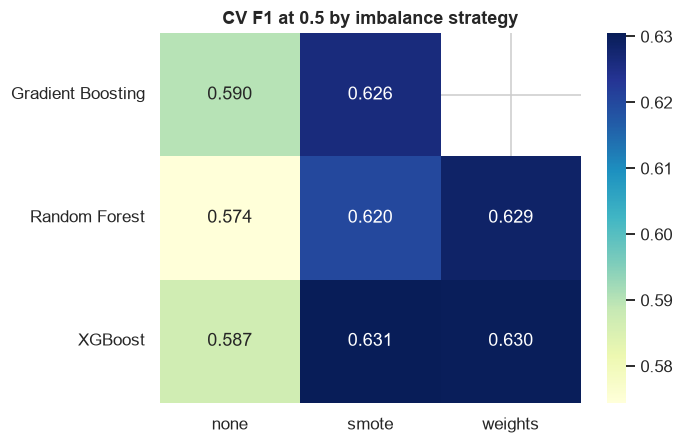

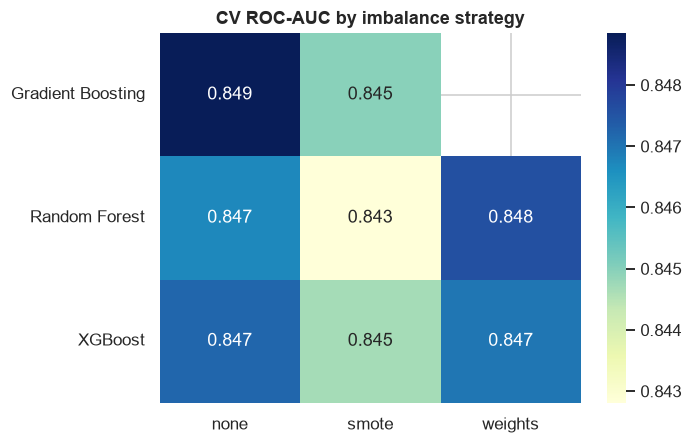

In [18]:
for metric, title in [
    ("cv_roc_auc", "CV ROC-AUC"),
    ("cv_pr_auc", "CV PR-AUC"),
    ("cv_f1", "CV F1 at 0.5 threshold"),
    ("cv_recall", "CV recall at 0.5 threshold"),
]:
    pivot = summary.pivot(index="model", columns="strategy", values=metric)
    display(pivot.style.set_caption(title).format("{:.4f}"))

plots.plot_heatmap(
    summary.pivot(index="model", columns="strategy", values="cv_f1"),
    "CV F1 at 0.5 by imbalance strategy",
    name="09_strategy_f1",
)
plots.plot_heatmap(
    summary.pivot(index="model", columns="strategy", values="cv_roc_auc"),
    "CV ROC-AUC by imbalance strategy",
    name="10_strategy_auc",
)

ROC-AUC is threshold-free, so imbalance handling barely moves it. Its effect shows up in **recall and F1 at the
default 0.5 threshold**, where class weights and SMOTE trade precision for recall. The threshold analysis in section 6
shows that a well-chosen threshold can recover most of this effect for any model.

### 5.2 Tuned models on the test set

In [19]:
tuned = tuning.collect_best(searches, summary)
display(
    tuning.best_per_model(summary)[
        ["model", "strategy", "cv_roc_auc", "cv_pr_auc", "cv_f1", "cv_recall", "best_params"]
    ]
)

tuned_results = evaluate.evaluate_models(tuned, X_test, y_test)
comparison = pd.concat([baseline_results.drop(index="Dummy"), tuned_results])
display(
    comparison[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]].sort_values(
        "roc_auc", ascending=False
    )
)

,model,strategy,cv_roc_auc,cv_pr_auc,cv_f1,cv_recall,best_params
0,Gradient Boosting,none,0.8488,0.6728,0.5902,0.5244,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est..."
1,Random Forest,weights,0.8476,0.6686,0.6286,0.7829,"{'max_depth': 10, 'max_features': 'sqrt', 'min..."
2,XGBoost,none,0.8472,0.6690,0.5867,0.5183,"{'colsample_bytree': 0.7, 'learning_rate': 0.0..."


,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
XGBoost (none),0.7979,0.6650,0.4813,0.5584,0.8456,0.6556
Gradient Boosting (none),0.7979,0.6580,0.4973,0.5665,0.8452,0.6562
Logistic Regression,0.8088,0.6660,0.5615,0.6093,0.8448,0.6418
Random Forest (weights),0.7586,0.5301,0.8004,0.6378,0.8438,0.6517
KNN,0.7681,0.5676,0.5312,0.5488,0.7831,0.5082
Decision Tree,0.7265,0.4846,0.4759,0.4802,0.6468,0.3706


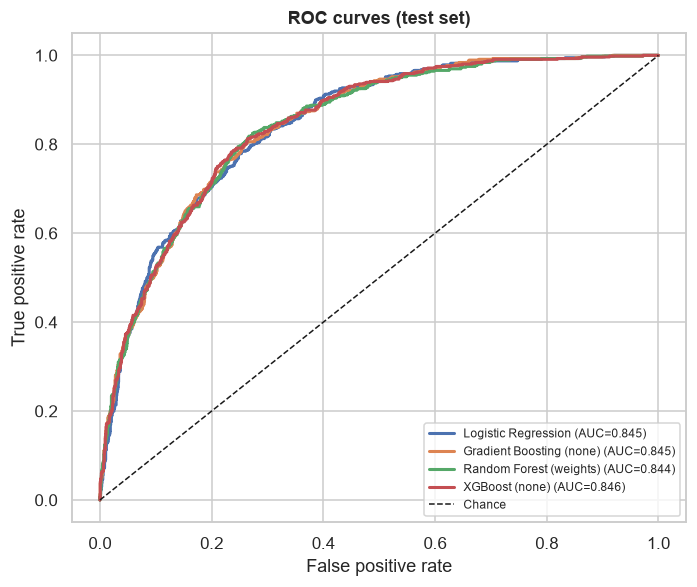

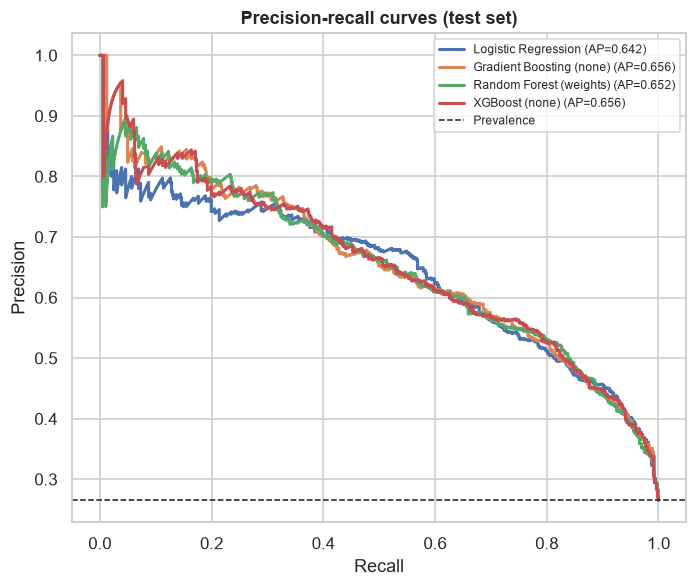

In [20]:
curve_models = {k: v for k, v in baselines.items() if k == "Logistic Regression"} | tuned
plots.plot_roc_curves(curve_models, X_test, y_test, name="11_roc_curves")
plots.plot_pr_curves(curve_models, X_test, y_test, name="12_pr_curves")

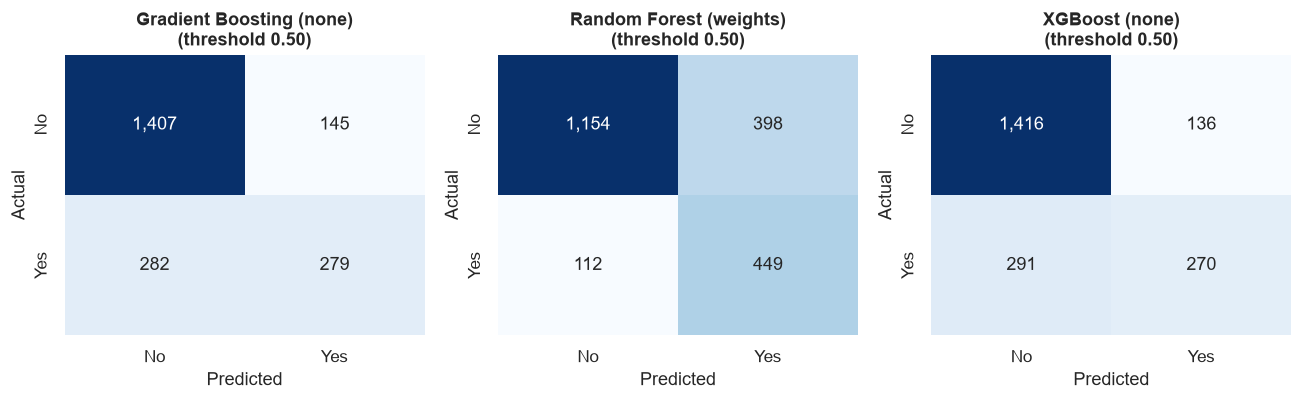

In [21]:
plots.plot_confusion_matrices(tuned, X_test, y_test, name="13_tuned_confusion_matrices")

## 6. Final model selection and threshold tuning

The final model is the (model, strategy) pair with the best **cross-validated ROC-AUC on the training set**.
The test set plays no part in the choice. The decision threshold is then tuned on **out-of-fold training
predictions** and the test set is used once, to report final performance.

In [22]:
final_model, final_strategy = tuning.select_final(summary)
final_label = f"{final_model} ({final_strategy})"
final_search = searches[(final_model, final_strategy)]
final_pipe = final_search.best_estimator_
print(f"Final model: {final_label}")
print(f"Best params: {final_search.best_params_}")

Final model: Gradient Boosting (none)
Best params: {'clf__learning_rate': 0.05, 'clf__max_depth': 2, 'clf__n_estimators': 200, 'clf__subsample': 0.8}


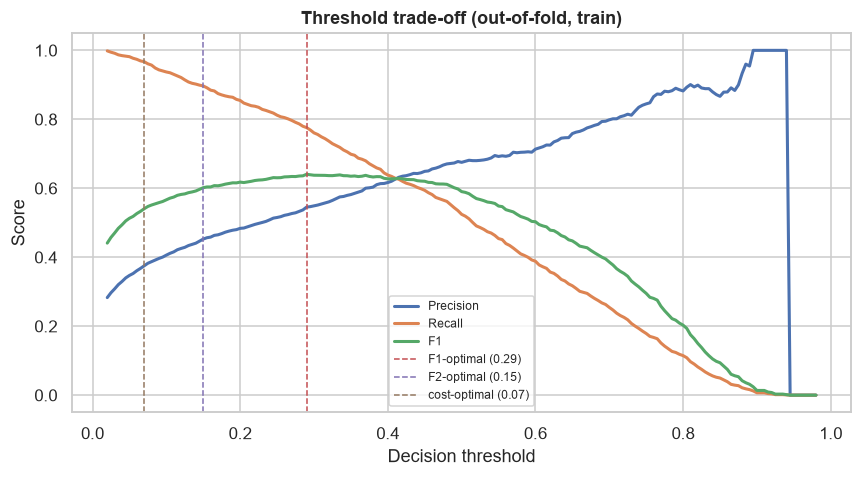

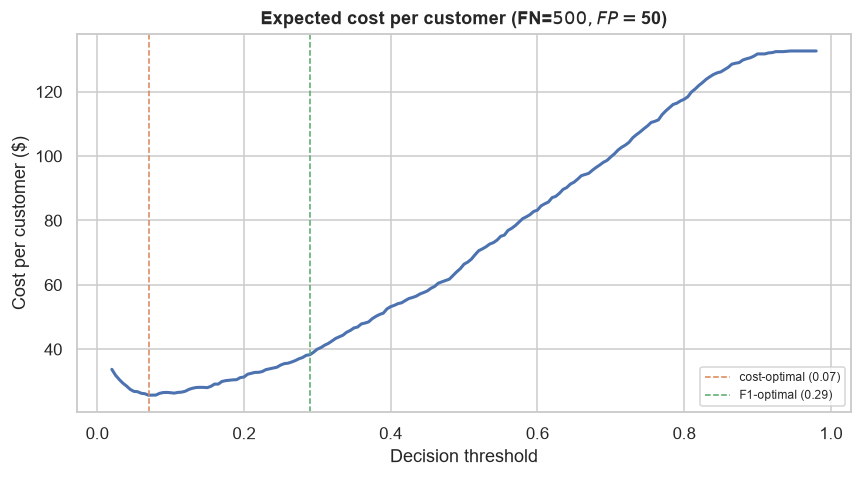

In [23]:
oof = thresholds.out_of_fold_proba(final_pipe, X_train, y_train)

t_f1, _ = thresholds.best_threshold(y_train, oof, beta=1.0)
t_f2, _ = thresholds.best_threshold(y_train, oof, beta=2.0)
curve = thresholds.cost_curve(y_train, oof, config.COST_FALSE_NEGATIVE, config.COST_FALSE_POSITIVE)
t_cost = thresholds.cost_optimal_threshold(curve)

marks = {"F1-optimal": t_f1, "F2-optimal": t_f2, "cost-optimal": t_cost}
plots.plot_threshold_tradeoff(y_train, oof, marks, name="14_threshold_tradeoff")
plots.plot_cost_curve(curve, {"cost-optimal": t_cost, "F1-optimal": t_f1}, name="15_cost_curve")

In [24]:
operating_points = {
    "default 0.50": 0.5,
    "F1-optimal": t_f1,
    "F2-optimal": t_f2,
    "cost-optimal": t_cost,
}
threshold_table = evaluate.threshold_comparison(final_pipe, X_test, y_test, operating_points)
display(threshold_table)

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp,cost_per_customer
operating point,,,,,,,,,,,,
default 0.50,0.5000,0.7979,0.6580,0.4973,0.5665,0.8452,0.6562,1407,145,282,279,70.1609
F1-optimal,0.2900,0.7596,0.5324,0.7772,0.6319,0.8452,0.6562,1169,383,125,436,38.6417
F2-optimal,0.1500,0.6805,0.4488,0.8913,0.5970,0.8452,0.6562,938,614,61,500,28.9636
cost-optimal,0.0700,0.5570,0.3715,0.9661,0.5366,0.8452,0.6562,635,917,19,542,26.1950


We use the **F1-optimal threshold** as the default operating point (balanced precision and recall).
If the retention offer is cheap relative to the value of a saved customer, the cost-optimal or F2-optimal
threshold is preferable. The cost figures in `config.py` are illustrative assumptions and should be replaced
with real business numbers.

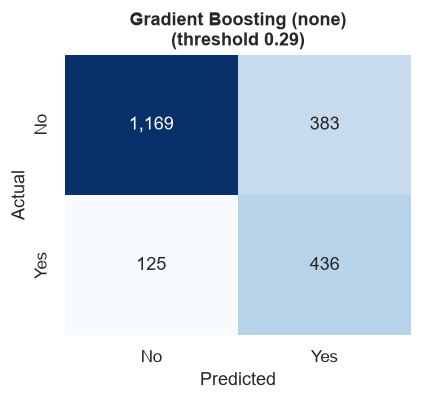

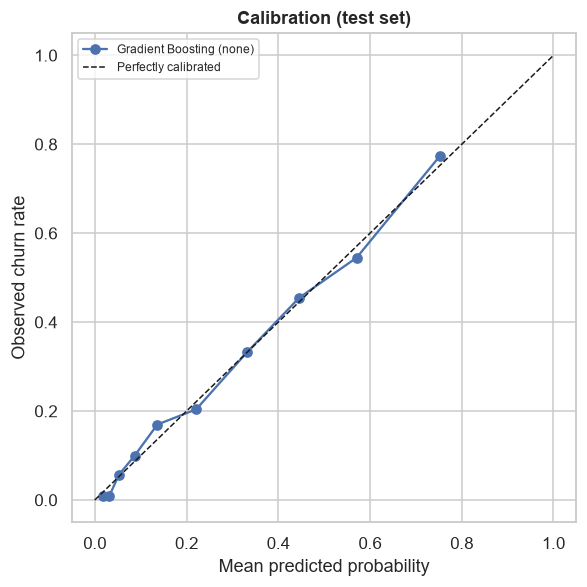

In [25]:
threshold = t_f1
plots.plot_confusion_matrices(
    {final_label: final_pipe}, X_test, y_test, thresholds={final_label: threshold}, name="16_final_confusion_matrix"
)
plots.plot_calibration({final_label: final_pipe}, X_test, y_test, name="17_calibration")

### 6.1 Lift and gains (how many churners do we catch by contacting the top-risk customers?)

In [26]:
test_prob = evaluate.positive_proba(final_pipe, X_test)
display(evaluate.decile_table(y_test, test_prob))

,customers,churners,avg_prob,churn_rate,lift,cum_capture
decile,,,,,,
1,212,164,0.7523,0.7736,2.9137,0.2923
2,211,115,0.5709,0.5450,2.0528,0.4973
3,211,96,0.4459,0.4550,1.7137,0.6684
4,211,70,0.3314,0.3318,1.2495,0.7932
5,212,44,0.2207,0.2075,0.7817,0.8717
6,211,35,0.1363,0.1659,0.6248,0.9340
7,211,21,0.0867,0.0995,0.3749,0.9715
8,211,12,0.0527,0.0569,0.2142,0.9929
9,211,2,0.0319,0.0095,0.0357,0.9964


## 7. Interpretation
### 7.1 Feature importance

,importance
Contract_Month-to-month,0.3399
tenure,0.1811
InternetService_Fiber optic,0.0961
OnlineSecurity_No,0.0908
MonthlyCharges,0.0639
TotalCharges,0.0524
TechSupport_No,0.0515
PaymentMethod_Electronic check,0.0485
PaperlessBilling_Yes,0.0217
MultipleLines_No,0.0105


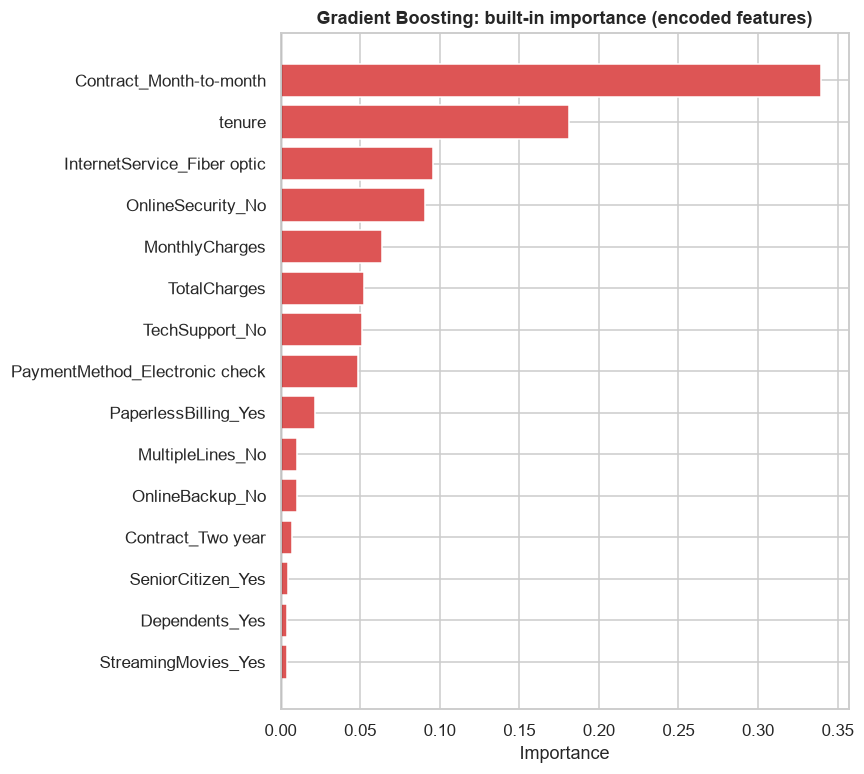

In [27]:
builtin = interpret.builtin_importance(final_pipe)
display(builtin.head(15).to_frame("importance"))
plots.plot_ranked_bar(
    builtin, f"{final_model}: built-in importance (encoded features)", "Importance", name="18_builtin_importance"
)

,importance_mean,importance_std
tenure,0.0560,0.0051
Contract,0.0511,0.0058
InternetService,0.0121,0.0024
MonthlyCharges,0.0080,0.0030
OnlineSecurity,0.0065,0.0023
PaymentMethod,0.0043,0.0009
TechSupport,0.0040,0.0013
MultipleLines,0.0027,0.0008
PaperlessBilling,0.0025,0.0016
n_addons,0.0020,0.0009


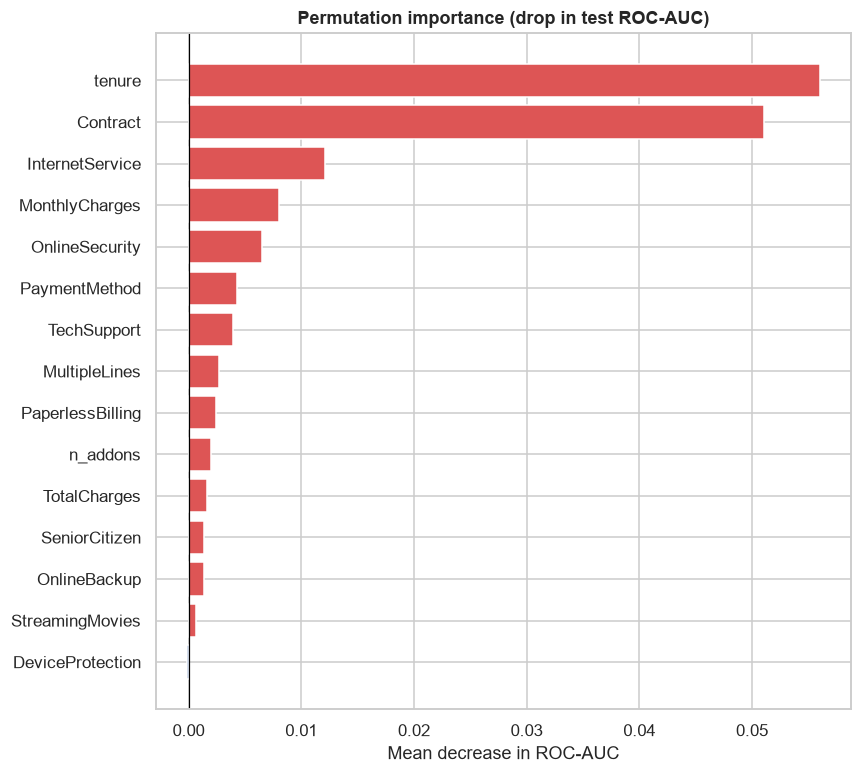

In [28]:
perm = interpret.permutation_table(final_pipe, X_test, y_test, scoring="roc_auc", n_repeats=20)
display(perm)
plots.plot_ranked_bar(
    perm["importance_mean"],
    "Permutation importance (drop in test ROC-AUC)",
    "Mean decrease in ROC-AUC",
    name="19_permutation_importance",
)

D:\DOCUMENTS\CollegeStuff\telco-churn\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


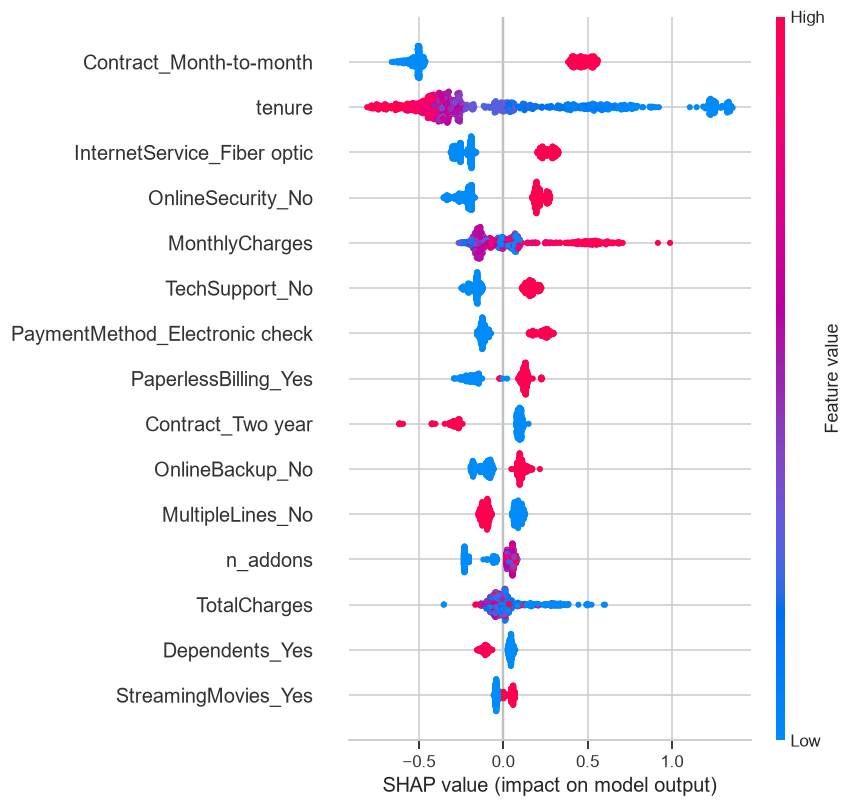

In [29]:
try:
    shap_values, shap_X = interpret.compute_shap(final_pipe, X_test)
    plots.plot_shap_summary(shap_values, shap_X, name="20_shap_summary")
except Exception as exc:  # SHAP is an optional extra; never block the notebook on it
    print(f"SHAP skipped: {type(exc).__name__}: {exc}")

### 7.2 Business insights

In [30]:
segments = {
    "Month-to-month contract": df["Contract"] == "Month-to-month",
    "Two-year contract": df["Contract"] == "Two year",
    "Tenure <= 12 months": df["tenure"] <= 12,
    "Fiber optic internet": df["InternetService"] == "Fiber optic",
    "Electronic check payment": df["PaymentMethod"] == "Electronic check",
    "No tech support": df["TechSupport"] == "No",
    "High-risk combo: M2M + fiber + tenure <= 12": (
        (df["Contract"] == "Month-to-month")
        & (df["InternetService"] == "Fiber optic")
        & (df["tenure"] <= 12)
    ),
}
display(eda.segment_table(df, segments))

,customers,share_of_base,churn_rate,lift_vs_overall
segment,,,,
Month-to-month contract,3875,0.5502,0.4271,1.6094
Two-year contract,1695,0.2407,0.0283,0.1067
Tenure <= 12 months,2186,0.3104,0.4744,1.7876
Fiber optic internet,3096,0.4396,0.4189,1.5787
Electronic check payment,2365,0.3358,0.4529,1.7065
No tech support,3473,0.4931,0.4164,1.5690
High-risk combo: M2M + fiber + tenure <= 12,916,0.1301,0.7020,2.6452


**Insights to write up (confirm each against the tables and plots above)**
- Contract type and tenure dominate: month-to-month customers in their first year churn at several times the base rate.
- Fiber optic customers churn more despite paying more. This points to a price/value or service-quality problem, not just a pricing one.
- Customers without tech support or online security churn more; bundling or promoting these add-ons is a candidate retention lever.
- Auto-pay customers churn less than electronic-check customers.
- `gender` shows no meaningful association with churn, so it should not drive any targeting.
- The decile table quantifies how much better model-based targeting is than random outreach.

## 8. Save the final model for the demo app

In [31]:
final_metrics = threshold_table.loc["F1-optimal"].to_dict()
artifacts.save_model(
    final_pipe,
    model_name=final_model,
    strategy=final_strategy,
    threshold=threshold,
    metrics=final_metrics,
    params=final_search.best_params_,
)

reloaded, card = artifacts.load_model()
assert np.allclose(reloaded.predict_proba(X_test)[:, 1], test_prob), "Reloaded model disagrees with in-memory model"
print("Saved and verified. Operating threshold:", round(card["threshold"], 3))

Saved and verified. Operating threshold: 0.29


## 9. Final model justification

- **Why this model:** highest cross-validated ROC-AUC on training data (selected without touching the test set),
  with test performance confirming it generalises (see section 5.2).
- **Why these metrics:** with ~26% churners, ROC-AUC and PR-AUC measure ranking quality independent of threshold,
  while recall/F1 at a tuned threshold measure the actual retention campaign.
- **Why this threshold:** tuned on out-of-fold training predictions, then reported once on the test set.

## 10. Limitations
- Single snapshot, no time dimension: no real forecasting horizon, and no way to detect concept drift. Churn drivers may change with pricing or competition.
- Features are account-level only (no usage, support-call, complaint or network-quality data), which caps achievable performance.
- The dataset is a synthetic IBM sample, so absolute performance will not transfer to a real operator.
- SMOTE interpolates one-hot and scaled features, creating synthetic points that are not valid customers; its benefit should be judged on CV, as done here.
- Predicting churn is not the same as predicting who is *persuadable*. Ranking by churn probability may spend offers on customers who would have stayed.
- Cost figures are assumptions. Test set has ~2,100 rows, so metric differences of about 1-2 points are within noise.
- Fairness: `gender` and `SeniorCitizen` are protected-style attributes. A production system needs a fairness review before use.

## 11. Future improvements
- Uplift modelling or A/B-tested retention offers to target persuadable customers.
- Behavioural time-series features (usage trends, support tickets, billing disputes) and survival analysis for *time to churn*.
- Probability calibration (isotonic/Platt) if probabilities will be used for expected-value calculations.
- Cost-sensitive learning with real customer-lifetime-value figures; monitoring for drift; scheduled retraining.